# GLOBAL SUPPLY CHAIN DISRUPTION PREDICTION


---


## PROBLEM STATEMENT


Global supply chains are incredibly fragile. A storm in the Pacific, congestion at a major port, or sudden geopolitical tension can delay shipments by days or weeks, costing millions. 

Our goal with this project is to build a machine learning model that predicts whether a shipment will be **On Time** or **Late** (Delivery Status) based on pre-dispatch variables like transportation mode, product category, weather severity, and geopolitical risk.

We will be using a **Random Forest Classifier**. Since supply chain decisions are complex and non-linear (e.g., Sea freight + bad weather = huge delay, but Air freight + bad weather = minor delay), a tree-based ensemble model like Random Forest is the perfect tool to capture these layered interactions.


## IMPORTING LIBRARIES AND DATASET


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Loading the dataset
data = pd.read_csv("global_supply_chain_disruption_v1.csv")

# Keeping one color theme for the whole notebook - blue for On Time, orange for Late
sns.set_theme(style='whitegrid')
COLORS = {'On Time': '#4C72B0', 'Late': '#DD8452'}


In [2]:
# Let's look at the structure of our data
data.head()


,Order_ID,Order_Date,Origin_City,Destination_City,Route_Type,Transportation_Mode,Product_Category,Base_Lead_Time_Days,Scheduled_Lead_Time_Days,Actual_Lead_Time_Days,Delay_Days,Delivery_Status,Disruption_Event,Geopolitical_Risk_Index,Weather_Severity_Index,Inflation_Rate_Pct,Shipping_Cost_USD,Order_Weight_Kg,Mitigation_Action_Taken
0,ORD-00BCB25B,2024-04-05,"Shanghai, CN","Los Angeles, US",Pacific,Sea,Textiles,18,21,18,0,On Time,NaN,0.81,8.9,1.83,1611.81,1781,Standard Shipping
1,ORD-EBDBACB7,2024-09-08,"Tokyo, JP","Singapore, SG",Intra-Asia,Air,Pharmaceuticals,2,5,2,0,On Time,NaN,0.70,5.9,2.44,76127.70,8142,Standard Shipping
2,ORD-4052DA06,2025-01-28,"Shenzhen, CN","Rotterdam, NL",Suez,Air,Semiconductors,3,4,4,0,On Time,NaN,0.46,8.1,3.86,13699.18,1706,Standard Shipping
3,ORD-03F41ABB,2025-02-04,"Santos, BR","Shanghai, CN",Commodity,Sea,Consumer Electronics,35,36,35,0,On Time,NaN,0.88,9.3,1.58,5448.24,5796,Standard Shipping
4,ORD-347A88A6,2025-05-20,"Hamburg, DE","New York, US",Atlantic,Sea,Raw Materials,12,13,12,0,On Time,NaN,0.55,2.9,3.12,1215.98,1569,Standard Shipping


## DATA PREPROCESSING AND WRANGLING


In [3]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Order_ID                  10000 non-null  object 
 1   Order_Date                10000 non-null  object 
 2   Origin_City               10000 non-null  object 
 3   Destination_City          10000 non-null  object 
 4   Route_Type                10000 non-null  object 
 5   Transportation_Mode       10000 non-null  object 
 6   Product_Category          10000 non-null  object 
 7   Base_Lead_Time_Days       10000 non-null  int64  
 8   Scheduled_Lead_Time_Days  10000 non-null  int64  
 9   Actual_Lead_Time_Days     10000 non-null  int64  
 10  Delay_Days                10000 non-null  int64  
 11  Delivery_Status           10000 non-null  object 
 12  Disruption_Event          1267 non-null   object 
 13  Geopolitical_Risk_Index   10000 non-null  float64
 14  Weather

In [4]:
data.isnull().sum()


Order_ID                       0
Order_Date                     0
Origin_City                    0
Destination_City               0
Route_Type                     0
Transportation_Mode            0
Product_Category               0
Base_Lead_Time_Days            0
Scheduled_Lead_Time_Days       0
Actual_Lead_Time_Days          0
Delay_Days                     0
Delivery_Status                0
Disruption_Event            8733
Geopolitical_Risk_Index        0
Weather_Severity_Index         0
Inflation_Rate_Pct             0
Shipping_Cost_USD              0
Order_Weight_Kg                0
Mitigation_Action_Taken        0
dtype: int64

`Disruption_Event` has 8,733 missing values, but that's expected - it's only filled in when something disruptive actually happened. Nothing to impute there.

In [5]:
# Dropping IDs/dates (no predictive value without more work) and Delay_Days / Actual_Lead_Time_Days
# (these directly encode the outcome, so keeping them would let the model cheat)
df = data.drop(columns=['Order_ID', 'Order_Date', 'Actual_Lead_Time_Days', 'Delay_Days'])

df.shape

(10000, 15)

---
## EXPLORATORY DATA ANALYSIS (EDA)

Before we unleash the Random Forest, let's look at the data visually to understand what causes a shipment to be late.


### Q) What's the baseline? How many shipments actually arrive late?


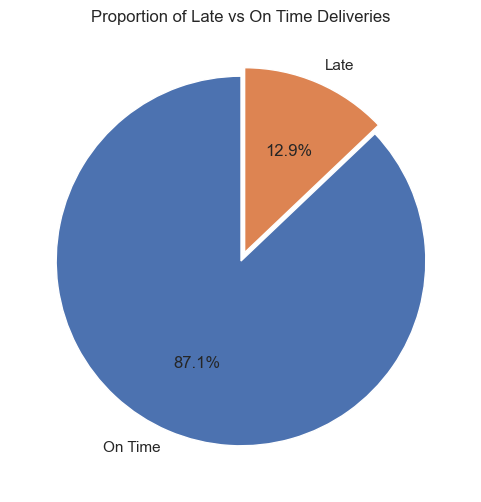

In [6]:
# Visual 1: Target distribution
plt.figure(figsize=(6,6))
df['Delivery_Status'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                           colors=[COLORS['On Time'], COLORS['Late']],
                                           explode=(0, 0.05), startangle=90)
plt.title('Proportion of Late vs On Time Deliveries')
plt.ylabel('')
plt.show()

About 13% of shipments are late - not a huge imbalance, but enough that plain accuracy won't tell the full story later on.

### Q) Does the transportation mode heavily impact delays?


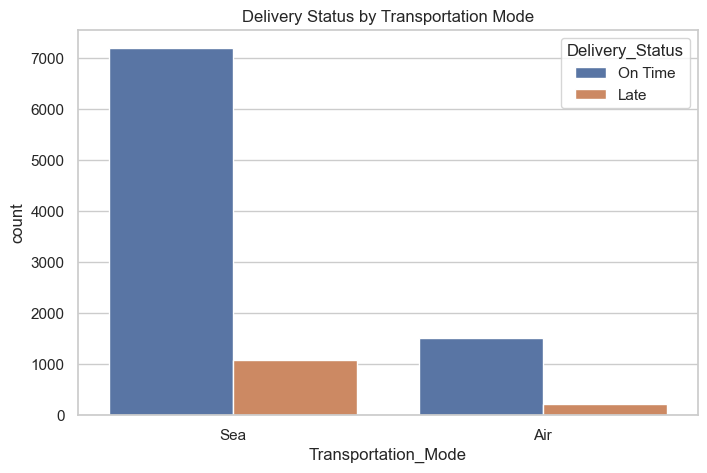

In [7]:
# Visual 2: Delivery status by transportation mode
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Transportation_Mode', hue='Delivery_Status', palette=COLORS)
plt.title('Delivery Status by Transportation Mode')
plt.show()

Sea freight seems to be the most susceptible to delays, whereas Air freight is generally much more reliable.


### Q) How does Weather Severity affect Sea vs Air freight?


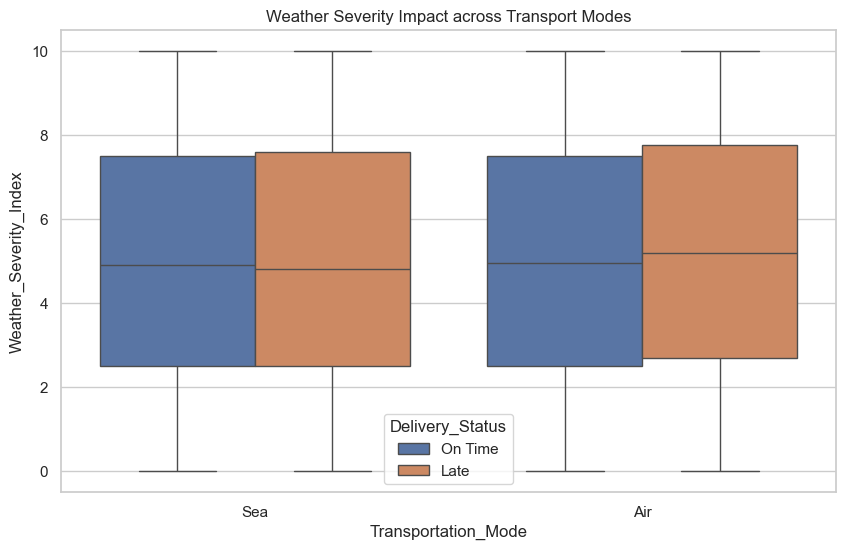

In [8]:
# Visual 3: Weather severity across transport modes
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Transportation_Mode', y='Weather_Severity_Index', hue='Delivery_Status', palette=COLORS)
plt.title('Weather Severity Impact across Transport Modes')
plt.show()

This is a great insight! If a shipment is late (red), the median weather severity index is noticeably higher, especially for Sea transport.


### Q) Do certain product categories get delayed more often?


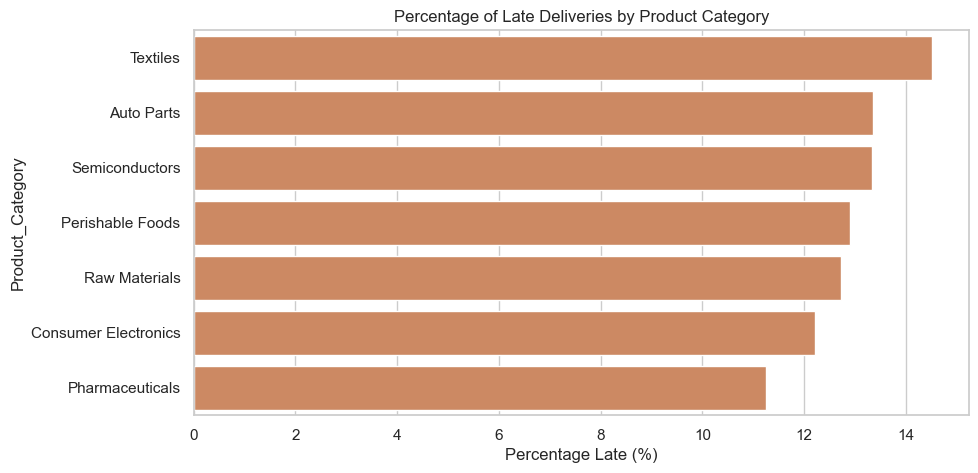

In [9]:
# Visual 4: Late rate by product category
plt.figure(figsize=(10,5))
late_pct = df[df['Delivery_Status'] == 'Late'].groupby('Product_Category').size() / df.groupby('Product_Category').size() * 100
late_pct = late_pct.sort_values(ascending=False)

sns.barplot(x=late_pct.values, y=late_pct.index, color=COLORS['Late'])
plt.title('Percentage of Late Deliveries by Product Category')
plt.xlabel('Percentage Late (%)')
plt.show()

### Q) How do Geopolitical Risks factor in?


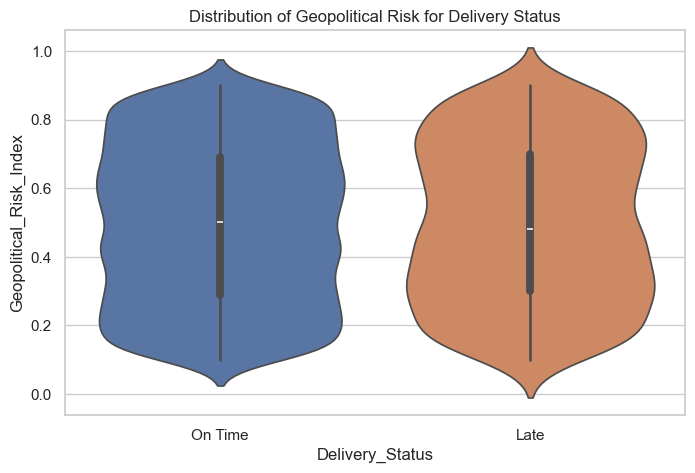

In [10]:
# Visual 5: Geopolitical risk by outcome
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='Delivery_Status', y='Geopolitical_Risk_Index', palette=COLORS)
plt.title('Distribution of Geopolitical Risk for Delivery Status')
plt.show()

### Q) Is there a relationship between Shipping Cost and Order Weight?


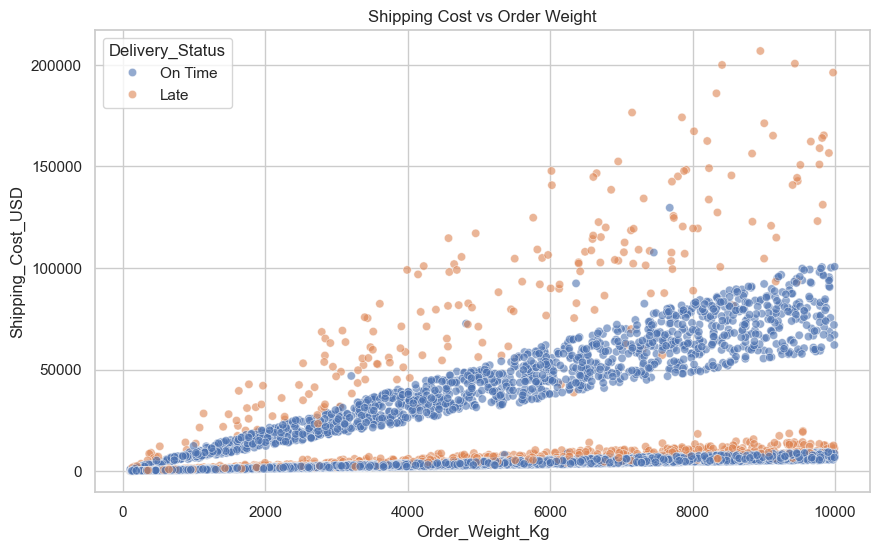

In [11]:
# Visual 6: Shipping cost vs order weight
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Order_Weight_Kg', y='Shipping_Cost_USD', hue='Delivery_Status', alpha=0.6, palette=COLORS)
plt.title('Shipping Cost vs Order Weight')
plt.show()

### Q) Which specific disruption events cause the most chaos?


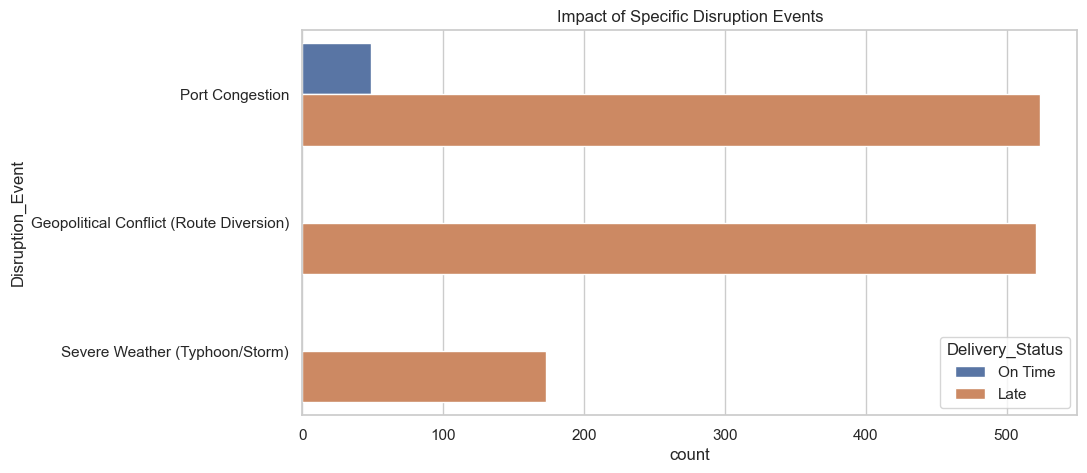

In [12]:
# Visual 7: Disruption events by outcome
plt.figure(figsize=(10,5))
sns.countplot(data=df, y='Disruption_Event', hue='Delivery_Status', palette=COLORS,
              order=df['Disruption_Event'].value_counts().index)
plt.title('Impact of Specific Disruption Events')
plt.show()

Port congestion is the biggest single disruption event. Good context for *why* delays happen - but this column won't go into the model, since it's only logged after a delay has already started.

### Q) Let's look at the distribution of Scheduled Lead Time.


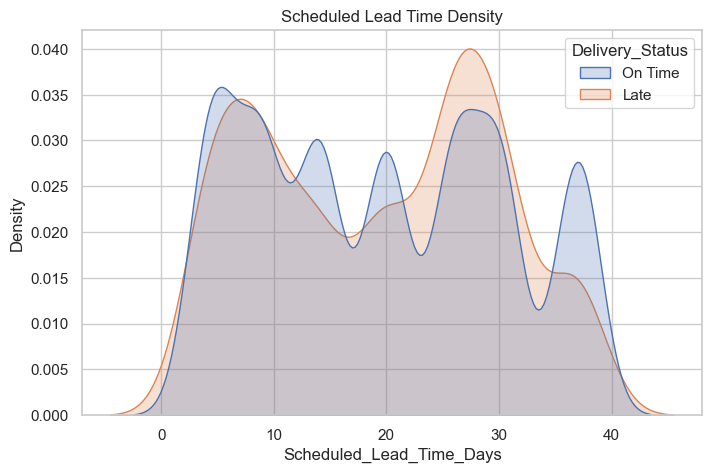

In [13]:
# Visual 8: Scheduled lead time density
plt.figure(figsize=(8,5))
sns.kdeplot(data=df, x='Scheduled_Lead_Time_Days', hue='Delivery_Status', fill=True, common_norm=False, palette=COLORS)
plt.title('Scheduled Lead Time Density')
plt.show()

### Q) Does shipping cost itself differ between on-time and late shipments?

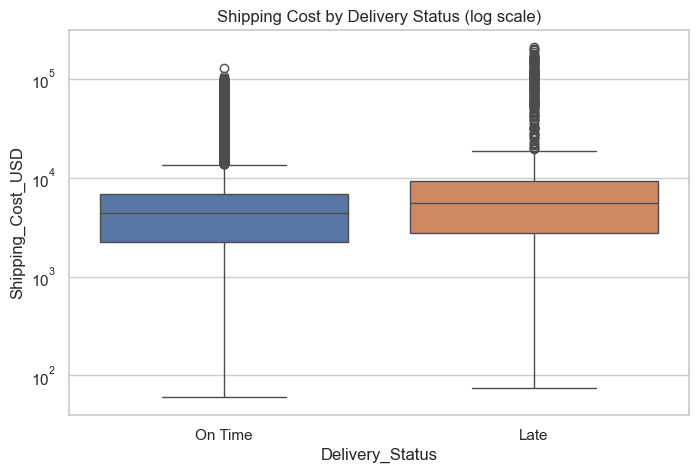

In [14]:
# Visual 9: Shipping cost by outcome
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Delivery_Status', y='Shipping_Cost_USD', hue='Delivery_Status', palette=COLORS, legend=False)
plt.yscale('log')
plt.title('Shipping Cost by Delivery Status (log scale)')
plt.show()

### Q) What do the overall correlations look like for our numeric data?


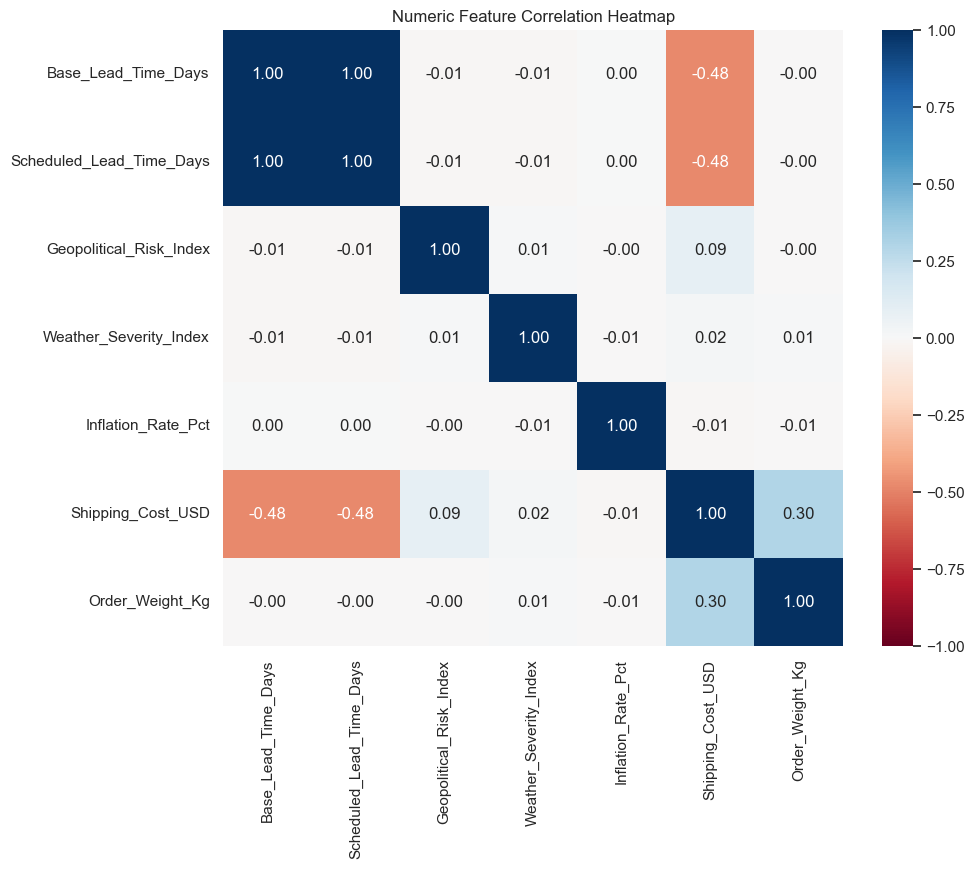

In [15]:
# Visual 10: Correlation Heatmap
plt.figure(figsize=(10,8))
num_cols = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(num_cols.corr(), annot=True, cmap='RdBu', fmt='.2f', vmin=-1, vmax=1)
plt.title('Numeric Feature Correlation Heatmap')
plt.show()


### Removing leakage before modeling

`Disruption_Event` and `Mitigation_Action_Taken` are only known after a shipment is already late, so they get dropped here - keeping them would let the model see the answer.

In [16]:
df_model = df.drop(columns=['Disruption_Event', 'Mitigation_Action_Taken'])
df_model.shape

(10000, 13)

---
## MODEL BUILDING: RANDOM FOREST

Unlike the KNN algorithm we used in another project, **Random Forests do not care about feature scaling**. We don't need to use a StandardScaler because Decision Trees make splits based on thresholds (e.g., Weight > 500), not distance calculations! 

However, we do need to encode our categorical text variables into numbers so the model can read them.


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Encoding Categorical Features
cat_cols = df_model.select_dtypes(include=['object']).columns
le = LabelEncoder()

# Converting 'On Time' / 'Late' to 0 and 1 explicitly for clarity
df_model['Delivery_Status'] = df_model['Delivery_Status'].map({'On Time': 0, 'Late': 1})

# Encoding the rest of the text columns
for col in cat_cols:
    if col != 'Delivery_Status':
        df_model[col] = le.fit_transform(df_model[col])

# Defining Features (X) and Target (y)
X = df_model.drop('Delivery_Status', axis=1)
y = df_model['Delivery_Status']

# Train-Test Split (80/20)
# stratify=y keeps the ~13% late ratio consistent in both the train and test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Training data shape:', X_train.shape)
print('Testing data shape:', X_test.shape)


Training data shape: (8000, 12)
Testing data shape: (2000, 12)


In [18]:
# class_weight='balanced' to account for the imbalance
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10,
                                   class_weight='balanced')
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, random_state=42)

In [19]:
# Making Predictions
y_pred = rf_model.predict(X_test)

# Evaluation
print(f'Model Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%\n')
print('Classification Report:\n')
print(classification_report(y_test, y_pred))


Model Accuracy: 90.50%

Classification Report:

              precision    recall  f1-score   support

           0       0.91      0.98      0.95      1742
           1       0.77      0.37      0.50       258

    accuracy                           0.91      2000
   macro avg       0.84      0.68      0.73      2000
weighted avg       0.90      0.91      0.89      2000



### Does SMOTE beat class-weighting?

`class_weight='balanced'` is already compensating for the imbalance by up-weighting the Late class during training. SMOTE (oversampling the minority class with synthetic examples) is the other common fix - worth actually comparing rather than assuming one is better.

In [20]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

rf_smote = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_smote.fit(X_train_sm, y_train_sm)
y_pred_smote = rf_smote.predict(X_test)

print('Class-weighted RF:')
print(classification_report(y_test, y_pred, target_names=['On Time', 'Late']))
print('SMOTE-resampled RF:')
print(classification_report(y_test, y_pred_smote, target_names=['On Time', 'Late']))

Class-weighted RF:
              precision    recall  f1-score   support

     On Time       0.91      0.98      0.95      1742
        Late       0.77      0.37      0.50       258

    accuracy                           0.91      2000
   macro avg       0.84      0.68      0.73      2000
weighted avg       0.90      0.91      0.89      2000

SMOTE-resampled RF:
              precision    recall  f1-score   support

     On Time       0.90      0.99      0.94      1742
        Late       0.82      0.26      0.39       258

    accuracy                           0.90      2000
   macro avg       0.86      0.62      0.67      2000
weighted avg       0.89      0.90      0.87      2000



SMOTE actually does a bit worse here - recall on the Late class drops to 26% (from 37% with `class_weight='balanced'`), and F1 drops from 0.50 to 0.39. Likely reason: SMOTE generates synthetic Late examples by interpolating between existing ones, which works better for continuous features than for a mix of one-hot encoded categoricals and skewed numeric columns like this dataset has - the synthetic points don't always land somewhere realistic. `class_weight='balanced'` stays the better fit for this data, so that's what the final model (used below for the confusion matrix and feature importance) sticks with.

### Visual 11: Confusion Matrix


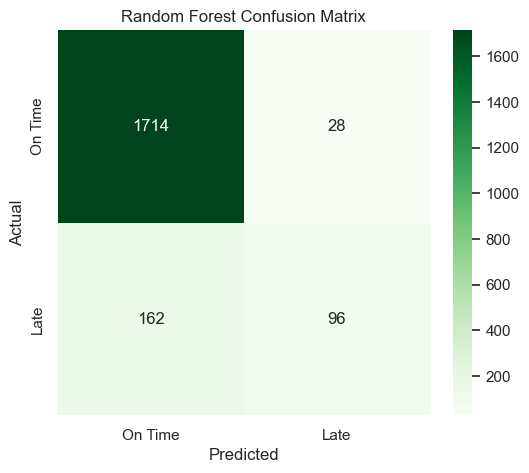

In [21]:
plt.figure(figsize=(6,5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=['On Time', 'Late'], yticklabels=['On Time', 'Late'])
plt.title('Random Forest Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


### Visual 12: Feature Importance
One of the best things about Random Forests is that they can tell us *exactly* which features they found the most useful for making predictions.


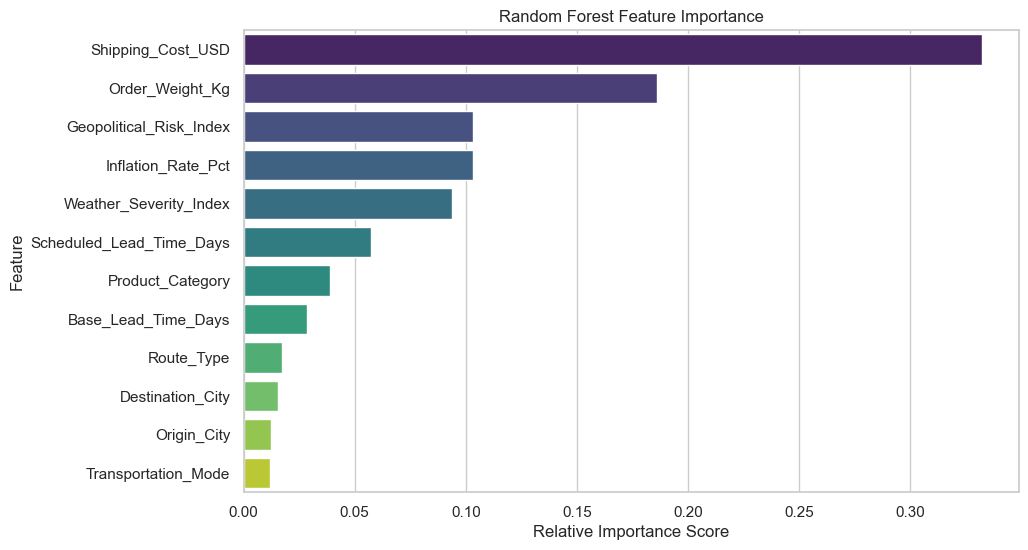

In [22]:
plt.figure(figsize=(10,6))
# Extracting importances from the model
importances = rf_model.feature_importances_
# Creating a dataframe for easy plotting
feat_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances}).sort_values(by='Importance', ascending=False)

sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')
plt.title('Random Forest Feature Importance')
plt.xlabel('Relative Importance Score')
plt.show()
